# Grouping and Aggregation in Pandas (groupby)

Most business questions are **per group**: revenue per zone, trips per hour, average tip per payment type. `groupby` follows the **split–apply–combine** pattern: split rows into groups, apply a function to each group, and combine the results.

**After this lesson you can:**

1. Aggregate with `groupby` and named aggregations.
2. Group by several keys and by time.
3. Use `transform` to add group statistics to every row, and `filter` to keep whole groups.
4. Build cross-tables with `pivot_table` and `crosstab`.

**Data:** NYC yellow taxi trips, January 2024, cleaned with the rules of Lesson 08.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"]
raw = pd.read_parquet(datasets.taxi("2024-01"), columns=COLS)        # NYC yellow taxi trips, January 2024
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

def clean_trips(df: pd.DataFrame) -> pd.DataFrame:
    """The cleaning rules of Lesson 08 in one function."""
    duration = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left")
          & duration.between(1, 180) & df["trip_distance"].between(0.1, 100)
          & df["fare_amount"].between(3, 500) & (df["total_amount"] > 0))
    return df[ok].assign(duration_min=duration[ok])

trips = clean_trips(raw)
print(f"{len(raw):,} raw trips -> {len(trips):,} clean trips")

trips = trips.assign(hour=trips["tpep_pickup_datetime"].dt.hour,
                     weekday=trips["tpep_pickup_datetime"].dt.day_name(),
                     borough=trips["PULocationID"].map(zones.set_index("LocationID")["Borough"]))

2,964,624 raw trips -> 2,855,769 clean trips


## 1. Basic Aggregation

`df.groupby(key)[column].agg(func)`. **Named aggregation** gives each result column a clear name: `agg(new_name=("column", "function"))`.

In [2]:
by_borough = (trips.groupby("borough")
              .agg(trips=("fare_amount", "size"),
                   revenue=("total_amount", "sum"),
                   median_fare=("fare_amount", "median"),
                   mean_distance=("trip_distance", "mean"),
                   median_minutes=("duration_min", "median"))
              .sort_values("trips", ascending=False))
by_borough["revenue_share_%"] = 100 * by_borough["revenue"] / by_borough["revenue"].sum()
by_borough.round(1)

,trips,revenue,median_fare,mean_distance,median_minutes,revenue_share_%
borough,,,,,,
Manhattan,2563152,58314285.4,12.1,2.3,10.9,74.8
Queens,255015,18464176.7,49.9,12.9,30.7,23.7
Brooklyn,21907,728720.8,25.5,6.2,24.9,0.9
Unknown,9464,255233.6,12.8,3.4,11.6,0.3
Bronx,5702,202142.4,31.5,7.8,32.1,0.3
Staten Island,32,2334.0,48.3,14.0,25.8,0.0
EWR,15,1396.6,75.0,12.1,27.4,0.0


Manhattan dominates the number of trips; Queens has longer and more expensive trips because of the two airports (JFK and LaGuardia).

## 2. Several Keys and Time Groups

Grouping by two keys returns a result with a **MultiIndex** (Lesson 13); `unstack` turns the inner key into columns. `pd.Grouper(freq=...)` or `resample` groups by time intervals.

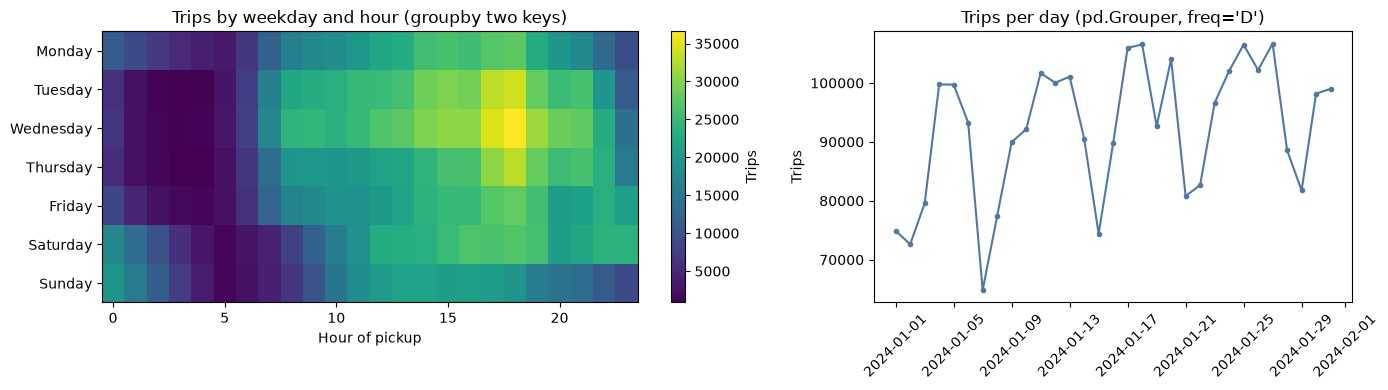

busiest hour: ('Wednesday', np.int32(18)) | quietest day: 2024-01-07 64817


In [3]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = trips.groupby(["weekday", "hour"]).size().unstack("hour").reindex(order)
daily = trips.groupby(pd.Grouper(key="tpep_pickup_datetime", freq="D")).agg(trips=("fare_amount", "size"),
                                                                            revenue=("total_amount", "sum"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.4, 1]})
im = ax1.imshow(heat, aspect="auto", cmap="viridis")
ax1.set(yticks=range(7), yticklabels=order, xlabel="Hour of pickup", title="Trips by weekday and hour (groupby two keys)")
fig.colorbar(im, ax=ax1, label="Trips")
ax2.plot(daily.index, daily["trips"], marker=".", color="#4E79A7")
ax2.set(title="Trips per day (pd.Grouper, freq='D')", ylabel="Trips")
ax2.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print("busiest hour:", heat.stack().idxmax(), "| quietest day:", daily["trips"].idxmin().date(), int(daily["trips"].min()))

The weekday pattern has a morning and an evening peak; weekend nights stay busy after midnight. The daily series has a clear dip on one day; checking the calendar of January 2024 for events (holidays, storms) is the next step of the analysis.

## 3. `transform`: Group Statistics on Every Row

`transform` returns a result with the **same index as the input**, so you can compare each row with its group: the share of a zone's revenue, the deviation from the zone median, a rank within the group.

In [4]:
trips["zone_median_fare"] = trips.groupby("PULocationID")["fare_amount"].transform("median")
trips["fare_vs_zone"] = trips["fare_amount"] / trips["zone_median_fare"]
trips["rank_in_zone"] = trips.groupby("PULocationID")["fare_amount"].rank(ascending=False, method="first")
print(trips[["PULocationID", "fare_amount", "zone_median_fare", "fare_vs_zone"]].head())
print(f"\ntrips costing more than 5x their zone's median fare: {(trips['fare_vs_zone'] > 5).sum():,}")

   PULocationID  fare_amount  zone_median_fare  fare_vs_zone
0           186         17.7              13.5      1.311111
1           140         10.0              12.1      0.826446
2           236         23.3              10.7      2.177570
3            79         10.0              12.1      0.826446
4           211          7.9              12.8      0.617188

trips costing more than 5x their zone's median fare: 32,875


## 4. `filter`: Keep or Drop Whole Groups

`filter(func)` keeps the groups for which `func(group)` is `True`. Example: keep only pickup zones with at least 1,000 trips, so that per-zone statistics are reliable.

In [5]:
busy = trips.groupby("PULocationID").filter(lambda g: len(g) >= 1000)
print(f"zones: {trips['PULocationID'].nunique()} -> {busy['PULocationID'].nunique()} with >= 1000 trips "
      f"({len(busy) / len(trips):.1%} of all trips)")

counts = trips["PULocationID"].value_counts()               # the same result without a Python function (faster)
busy_fast = trips[trips["PULocationID"].isin(counts[counts >= 1000].index)]
print("same rows:", len(busy) == len(busy_fast))

zones: 256 -> 69 with >= 1000 trips (98.6% of all trips)


same rows: True


## 5. `pivot_table` and `crosstab`

`pivot_table` is `groupby` + `unstack` in one call, with margins (totals). `crosstab` counts combinations of two categories, optionally normalised to shares.

In [6]:
PAYMENT = {1: "card", 2: "cash", 3: "no charge", 4: "dispute"}
trips["payment"] = trips["payment_type"].map(PAYMENT).fillna("other")
pt = trips.pivot_table(index="borough", columns="payment", values="total_amount", aggfunc="median", margins=True).round(2)
print(pt, "\n")
ct = pd.crosstab(trips["borough"], trips["payment"], normalize="index").round(3)
ct

payment          card   cash  dispute  no charge  other    All
borough                                                       
Bronx           36.00  16.60    32.55      15.30  28.05  34.00
Brooklyn        29.00  20.20    20.90      17.45  31.53  29.00
EWR            102.76  64.30    37.90        NaN    NaN  92.25
Manhattan       19.70  16.10    15.70      14.70  21.74  19.30
Queens          76.65  54.65    55.75      43.88  33.37  72.84
Staten Island  106.74   7.30    58.00      23.10  39.89  50.86
Unknown         20.16  16.80    21.30      18.20  20.93  19.68
All             20.64  16.80    17.10      15.70  22.20  20.16 



payment,card,cash,dispute,no charge,other
borough,,,,,
Bronx,0.778,0.073,0.004,0.004,0.142
Brooklyn,0.663,0.081,0.006,0.003,0.247
EWR,0.800,0.133,0.067,0.000,0.000
Manhattan,0.807,0.143,0.007,0.003,0.040
Queens,0.775,0.191,0.012,0.005,0.017
Staten Island,0.281,0.031,0.031,0.094,0.562
Unknown,0.799,0.174,0.004,0.006,0.017


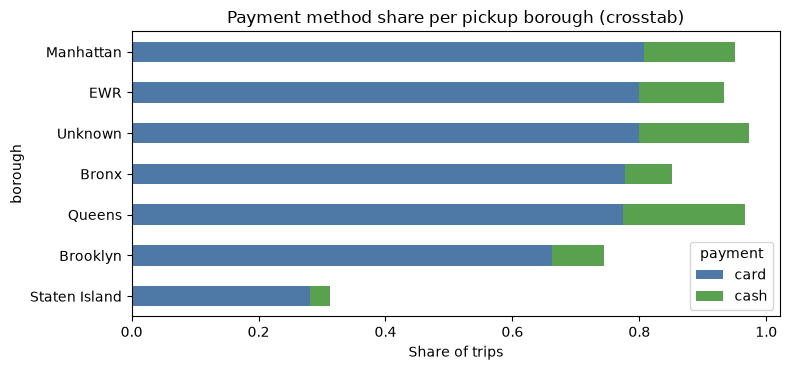

In [7]:
ax = ct.drop(columns=[c for c in ct.columns if c not in ("card", "cash")]).sort_values("card").plot.barh(
    stacked=True, figsize=(8, 3.8), color=["#4E79A7", "#59A14F"], title="Payment method share per pickup borough (crosstab)")
ax.set_xlabel("Share of trips")
plt.tight_layout()
plt.show()

## 6. Performance Notes

- Built-in aggregations (`"sum"`, `"mean"`, `"median"`, `"size"`) run in compiled code; a Python `lambda` in `agg` or `apply` runs Python code once per group and is slower; the gap grows with the number of groups.
- `observed=True` (the pandas 3 default) skips empty combinations of categorical keys.
- For hundreds of millions of rows, use Polars or DuckDB (Lessons 16–18); the `group_by` logic is the same.

In [8]:
t = time.perf_counter(); trips.groupby("PULocationID")["fare_amount"].mean(); fast = time.perf_counter() - t
t = time.perf_counter(); trips.groupby("PULocationID")["fare_amount"].agg(lambda s: s.sum() / len(s)); slow = time.perf_counter() - t
print(f"built-in mean {fast * 1000:.0f} ms | Python lambda {slow * 1000:.0f} ms ({slow / fast:.0f}x slower)")

built-in mean 36 ms | Python lambda 119 ms (3x slower)


*Insight: For every group question, decide three things: the group key, the measure, and the aggregation. Use named aggregations for readable results, `transform` to compare rows with their group, and built-in aggregation functions instead of lambdas.*

## Real-World Use Case or Analogy

`groupby` is like **sorting receipts into envelopes** by shop, then writing the total on each envelope (aggregation), or writing on each receipt what share of its envelope it represents (transform).

Taxi and ride-hailing companies use exactly these tables to plan supply by zone and hour, set surge prices and staff airports. SQL's `GROUP BY` and window functions (M07) express the same logic in a database.